In [1]:
import pandas as pd
import numpy as np 
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("Powerplant dataset.csv")

In [3]:
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [4]:
df.isnull().sum()

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [5]:
df.describe()

,AT,V,AP,RH,PE
count,9568.000000,9568.000000,9568.000000,9568.000000,9568.000000
mean,19.651231,54.305804,1013.259078,73.308978,454.365009
std,7.452473,12.707893,5.938784,14.600269,17.066995
min,1.810000,25.360000,992.890000,25.560000,420.260000
25%,13.510000,41.740000,1009.100000,63.327500,439.750000
50%,20.345000,52.080000,1012.940000,74.975000,451.550000
75%,25.720000,66.540000,1017.260000,84.830000,468.430000
max,37.110000,81.560000,1033.300000,100.160000,495.760000


In [6]:
# AT => temperature
# V => vacuum
# AP => pressure
# RH => humidity

# PE => produced energy

In [7]:
X = df.drop("PE" , axis = 1)
y = df["PE"]

In [8]:
# split our data
X_train , X_test , y_train , y_test = train_test_split(X,y,
                                                       random_state=42 , test_size= 0.3)

In [9]:
df.shape

(9568, 5)

In [10]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled=  scaler.fit_transform(X_train)
x_test_scaled = scaler.transform(X_test)

In [11]:
x_test_scaled

array([[ 1.35027377,  0.23835089, -1.2868797 , -1.1152662 ],
       [ 0.81612819,  1.36219539, -0.74354734,  0.25518223],
       [-0.23877586, -0.73921294,  1.9883008 , -0.20689783],
       ...,
       [ 0.23512774,  0.27059555,  0.93538342, -0.23848131],
       [-1.79971257, -1.42106962,  2.6025026 ,  1.16698358],
       [ 1.16285427,  0.78729663, -0.34195385, -0.32361939]],
      shape=(2871, 4))

In [12]:
import torch
import torch.nn as nn 

X_train_tensor = torch.tensor(X_train_scaled , dtype= torch.float32)
y_train_tensor = torch.tensor(y_train.values , dtype=torch.float32).view(-1,1)

X_test_tensor = torch.tensor(x_test_scaled , dtype= torch.float32)
y_test_tensor = torch.tensor(y_test.values , dtype=torch.float32).view(-1,1)

In [13]:
type(X_train_scaled)

numpy.ndarray

In [14]:
type(y_train)
y_train.shape

(6697,)

In [15]:
from torch.utils.data import TensorDataset , DataLoader

train_dataset = TensorDataset(X_train_tensor , y_train_tensor)
test_dataset = TensorDataset(X_test_tensor , y_test_tensor)

In [16]:
train_loder = DataLoader(train_dataset , batch_size=32 , shuffle= True)
test_loder = DataLoader(test_dataset , batch_size=32 )

### Deep Learning 

In [17]:
# define our ANN model


    # define our ANN model
class ANN(nn.Module):
        def __init__(self):
            super(ANN ,self).__init__()
            self.model = nn.Sequential(
                #  1st hidden layer 
                nn.Linear(X_train_tensor.shape[1], 6),
                nn.ReLU(),
                # 2nd hidden layer 
                nn.Linear(6, 6),
                nn.ReLU(),
                # output layer
                nn.Linear(6, 1)
            )

        def forward(self, x):
            return self.model(x)


In [18]:
import torch.optim as optim 

model = ANN()

# loss fuction , optimizer use karege 
crietrion = nn.MSELoss()

optimizer = optim.Adam(model.parameters())

In [19]:
# train the ANN
train_loss = []
val_loss = []

best_val_loss = float("inf")

epochs = 100
for epoch in range(epochs):
    model.train()
    running_loss = 0.0 # total training loss for 1 epoch 

    for xb ,yb in train_loder:
        # xb = feature of 1 batch(i/p)
        # yb = labels of 1 batch (o/p)
        optimizer.zero_grad()

        outputs = model(xb) # forward propa.... predicted output for this batch
        loss = crietrion(outputs , yb)# compute loss
        loss.backward() # backward propa... compute gradient 
        optimizer.step() # parameter update 

        running_loss += loss.item() # loss is a tensor => py float 


    epoch_train_loss = running_loss / len(train_loder)
    train_loss.append(epoch_train_loss)  

    # validation

    model.eval()
    running_val_loss = 0.0  

    with torch.no_grad(): # no graident compute 
        for xb , yb in test_loder:
            outputs = model(xb)
            loss = crietrion(outputs , yb)

            running_val_loss += loss
    epoch_val_loss = running_val_loss / len(test_loder)
    val_loss.append(epoch_val_loss) 

    print (f" epoch  {epoch +1 } /{epochs} ==> train loss = {epoch_train_loss} & validation loss = {epoch_val_loss}")

    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict() , "best_model.pt")# extension to save model .pt or .pth

 epoch  1 /100 ==> train loss = 206253.28058035715 & validation loss = 203897.21875
 epoch  2 /100 ==> train loss = 196707.03072916667 & validation loss = 185499.703125
 epoch  3 /100 ==> train loss = 166583.83430059525 & validation loss = 144035.484375
 epoch  4 /100 ==> train loss = 118441.87433035714 & validation loss = 92889.5859375
 epoch  5 /100 ==> train loss = 72070.4783110119 & validation loss = 54731.5390625
 epoch  6 /100 ==> train loss = 43319.03669084822 & validation loss = 34800.6640625
 epoch  7 /100 ==> train loss = 28825.35562686012 & validation loss = 24481.22265625
 epoch  8 /100 ==> train loss = 21238.645014880953 & validation loss = 18928.26171875
 epoch  9 /100 ==> train loss = 16946.651027715772 & validation loss = 15284.0751953125
 epoch  10 /100 ==> train loss = 13681.321193731399 & validation loss = 12101.3818359375
 epoch  11 /100 ==> train loss = 10704.90087890625 & validation loss = 9221.5703125
 epoch  12 /100 ==> train loss = 8080.960728236607 & validatio

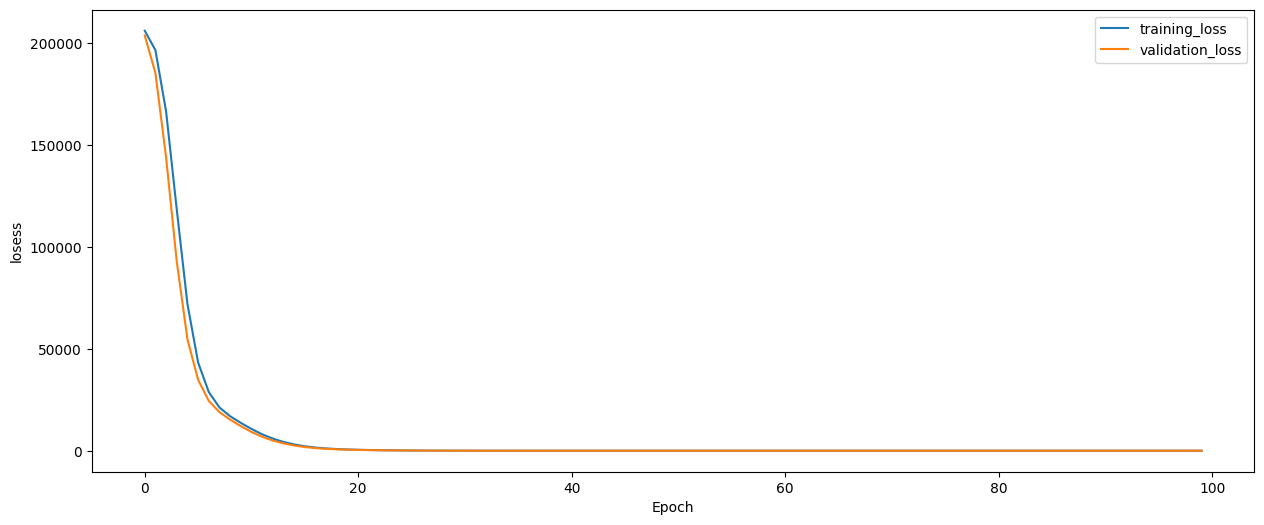

In [27]:
import matplotlib.pyplot as plt 

loss_df = pd.DataFrame({
    "training_loss" : train_loss,
    "validation_loss" : val_loss
})
plt.figure(figsize= (15,6))
plt.plot(loss_df["training_loss"], label="training_loss")
plt.plot(loss_df["validation_loss"] , label = "validation_loss")

plt.xlabel("Epoch")
plt.ylabel("losess")

plt.legend()

In [21]:
# loading the best model 
model.load_state_dict(torch.load("best_model.pt"))

<All keys matched successfully>

In [22]:
# Evaluation

model.eval()
with torch.no_grad():
    train_preds = model(X_train_tensor)
    test_preds = model(X_test_tensor)

    train_mse_loss = crietrion(train_preds, y_train_tensor)
    test_mse_loss = crietrion(test_preds, y_test_tensor)

print("Training MSE:", train_mse_loss.item())
print("Testing MSE:", test_mse_loss.item())

Training MSE: 20.585350036621094
Testing MSE: 19.303298950195312


In [23]:
from sklearn.metrics import r2_score
print ("r^2 score =", r2_score(y_test , test_preds) )

r^2 score = 0.932966980095775


In [24]:
predicted_df = pd.DataFrame(test_preds.numpy() ,columns= ["Peridected value"])
actual_df = pd.DataFrame(y_test.values ,columns= ["Actual value"])

pd.concat([predicted_df ,actual_df] , axis=1)

,Peridected value,Actual value
0,434.995636,433.27
1,436.891968,438.16
2,461.663513,458.42
3,476.813110,480.82
4,435.297424,441.41
...,...,...
2866,480.667419,480.31
2867,453.011932,446.77
2868,450.939270,454.66
2869,484.340088,483.77
